[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nahuelcosta/generative-networks/blob/main/transformers/language_model.ipynb)

This notebooks is part of the [Generative Networks course](https://www.nahuelcosta.com/teaching/generative-networks).

# Training a Tiny Transformer Language Model

In this tutorial we train a decoder-only Transformer to generate Shakespeare-like text. Unlike a pretrained library model, every part of this pipeline is visible:

- train a byte-level BPE tokenizer;
- create teacher-forced input/target batches;
- combine token and learned positional embeddings;
- run a causal stack of PyTorch Transformer layers;
- minimize next-token cross-entropy;
- generate one token at a time with greedy, temperature, or top-k sampling.

The model is intentionally small. It can learn formatting, names, fragments, and local style, but it is not expected to produce consistently meaningful dialogue.

## 0. Dependencies

In [1]:
# Install only missing packages. Colab and most course environments already provide them.
import importlib.util
import subprocess
import sys

packages = {"torch": "torch", "matplotlib": "matplotlib", "numpy": "numpy"}
missing = [pip_name for import_name, pip_name in packages.items()
           if importlib.util.find_spec(import_name) is None]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


## 1. Imports and Reproducibility

In [2]:
import hashlib
import math
import os
import random
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Configuration

The default configuration targets roughly 5–10 minutes on a free Colab GPU. For a quick pipeline check, set the environment variable `FAST_DEV_RUN=1` before starting the kernel, or change `fast_dev_run` below to `True`. Smoke mode reduces data, batch, context, evaluation, and optimization steps while retaining the same model architecture.

In [3]:
fast_dev_run = os.environ.get("FAST_DEV_RUN", "0") == "1"

project_root = Path.cwd().parent if Path.cwd().name == "transformers" else Path.cwd()
output_dir = project_root / "transformers" / "outputs" / "tiny_shakespeare_lm"
output_dir.mkdir(parents=True, exist_ok=True)

target_vocab_size = 384       # 256 byte tokens + 128 learned merges
tokenizer_training_characters = 100_000
context_length = 128
batch_size = 64
d_model = 128
num_heads = 4
num_layers = 3
feedforward_dim = 512
dropout = 0.1
learning_rate = 3e-4
max_steps = 2_000
eval_interval = 200
eval_batches = 20
gradient_clip = 1.0

if fast_dev_run:
    tokenizer_training_characters = 20_000
    context_length = 32
    batch_size = 4
    max_steps = 4
    eval_interval = 2
    eval_batches = 1

checkpoint_path = output_dir / "best_tiny_transformer.pt"
print("FAST_DEV_RUN:", fast_dev_run)

FAST_DEV_RUN: False


## 3. Load Tiny Shakespeare

The repository bundles the corpus so the normal path is offline and reproducible. If a notebook opened directly in Colab cannot see the repository files, the fallback downloads the identical canonical file and then verifies its SHA-256 checksum.

Tiny Shakespeare is distributed by Andrej Karpathy's [char-rnn project](https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare) and contains public-domain Shakespeare text.

In [5]:
CORPUS_URL = (
    "https://raw.githubusercontent.com/karpathy/char-rnn/"
    "master/data/tinyshakespeare/input.txt"
)
CORPUS_SHA256 = "86c4e6aa9db7c042ec79f339dcb96d42b0075e16b8fc2e86bf0ca57e2dc565ed"


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as file_handle:
        for chunk in iter(lambda: file_handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


corpus_candidates = [
    Path.cwd() / "assets" / "tiny_shakespeare.txt",
    Path.cwd() / "transformers" / "assets" / "tiny_shakespeare.txt",
]
corpus_path = next((path for path in corpus_candidates if path.exists()), None)

if corpus_path is None:
    corpus_path = Path.cwd() / "tiny_shakespeare.txt"
    print(f"Bundled corpus not found; downloading {CORPUS_URL}")
    urllib.request.urlretrieve(CORPUS_URL, corpus_path)

actual_checksum = sha256_file(corpus_path)
if actual_checksum != CORPUS_SHA256:
    raise ValueError(
        f"Corpus checksum mismatch: expected {CORPUS_SHA256}, got {actual_checksum}"
    )

text = corpus_path.read_text(encoding="utf-8")
split_index = int(0.9 * len(text))
train_text = text[:split_index]
validation_text = text[split_index:]

print(f"Corpus path: {corpus_path}")
print(f"Characters: {len(text):,}")
print(f"Train/validation characters: {len(train_text):,} / {len(validation_text):,}")
print(text[:250])
assert train_text + validation_text == text

Corpus path: /home/nahuel/generative-networks/transformers/assets/tiny_shakespeare.txt
Characters: 1,115,394
Train/validation characters: 1,003,854 / 111,540
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



## 4. Train a Byte-Level BPE Tokenizer

Token IDs are categorical vocabulary indices, not numerical measurements. We begin with all 256 UTF-8 byte values, then learn the most frequent adjacent merges from a bounded prefix of the **training split only**. Validation text must not influence tokenizer training.

The implementation favors clarity over production speed. Deterministic tie-breaking makes repeated runs learn the same merge table.

In [6]:
class BytePairTokenizer:
    def __init__(self, merges=None):
        self.merges = [tuple(pair) for pair in (merges or [])]
        self._rebuild_vocabulary()

    @classmethod
    def train(cls, text, vocab_size):
        if vocab_size < 256:
            raise ValueError("vocab_size must include the 256 byte tokens")
        token_ids = list(text.encode("utf-8"))
        merges = []

        for new_id in range(256, vocab_size):
            pair_counts = Counter(zip(token_ids, token_ids[1:]))
            if not pair_counts:
                break
            best_count = max(pair_counts.values())
            best_pair = min(
                pair for pair, count in pair_counts.items() if count == best_count
            )
            token_ids = cls._merge_pair(token_ids, best_pair, new_id)
            merges.append(best_pair)

        return cls(merges)

    @staticmethod
    def _merge_pair(token_ids, pair, new_id):
        merged = []
        index = 0
        while index < len(token_ids):
            if (
                index + 1 < len(token_ids)
                and (token_ids[index], token_ids[index + 1]) == pair
            ):
                merged.append(new_id)
                index += 2
            else:
                merged.append(token_ids[index])
                index += 1
        return merged

    def _rebuild_vocabulary(self):
        self.vocabulary = {token_id: bytes([token_id]) for token_id in range(256)}
        for new_id, (left, right) in enumerate(self.merges, start=256):
            self.vocabulary[new_id] = self.vocabulary[left] + self.vocabulary[right]

    @property
    def vocab_size(self):
        return len(self.vocabulary)

    def encode(self, text):
        token_ids = list(text.encode("utf-8"))
        for new_id, pair in enumerate(self.merges, start=256):
            token_ids = self._merge_pair(token_ids, pair, new_id)
        return token_ids

    def decode(self, token_ids):
        byte_string = b"".join(self.vocabulary[int(token_id)] for token_id in token_ids)
        # Valid encoded text round-trips exactly. Arbitrary model samples can contain
        # incomplete UTF-8 sequences, which are rendered with the replacement character.
        return byte_string.decode("utf-8", errors="replace")

    def state_dict(self):
        return {"merges": [list(pair) for pair in self.merges]}

    @classmethod
    def from_state_dict(cls, state):
        return cls(merges=[tuple(pair) for pair in state["merges"]])

In [7]:
tokenizer_training_text = train_text[:tokenizer_training_characters]
tokenizer = BytePairTokenizer.train(tokenizer_training_text, target_vocab_size)

unicode_check = "First Citizen: ¡Attention works! 🤖"
unicode_ids = tokenizer.encode(unicode_check)
assert tokenizer.decode(unicode_ids) == unicode_check
assert tokenizer.vocab_size == target_vocab_size

byte_count = len(tokenizer_training_text.encode("utf-8"))
token_count = len(tokenizer.encode(tokenizer_training_text))
print(f"Vocabulary size: {tokenizer.vocab_size}")
print(f"Training subset bytes: {byte_count:,}")
print(f"Training subset BPE tokens: {token_count:,}")
print(f"Compression: {byte_count / token_count:.2f} bytes/token")
print("Round trip:", tokenizer.decode(unicode_ids))

Vocabulary size: 384
Training subset bytes: 100,000
Training subset BPE tokens: 57,023
Compression: 1.75 bytes/token
Round trip: First Citizen: ¡Attention works! 🤖


## 5. Encode the Corpus and Build Batches

We preserve chronological order in the train/validation split. Each batch samples random windows. Targets are the exact same windows shifted one token to the left:

- input: `To be, or not to b`
- target: `o be, or not to be`

Teacher forcing supplies every real previous token during training. The causal mask will ensure each position can use only itself and earlier positions.

In [8]:
model_train_text = train_text[:50_000] if fast_dev_run else train_text
model_validation_text = validation_text[:10_000] if fast_dev_run else validation_text
train_tokens = torch.tensor(tokenizer.encode(model_train_text), dtype=torch.long)
validation_tokens = torch.tensor(tokenizer.encode(model_validation_text), dtype=torch.long)

print(f"Encoded train tokens: {len(train_tokens):,}")
print(f"Encoded validation tokens: {len(validation_tokens):,}")
assert len(train_tokens) > context_length
assert len(validation_tokens) > context_length

Encoded train tokens: 604,237
Encoded validation tokens: 68,051


In [9]:
batch_generators = {
    "train": torch.Generator().manual_seed(SEED),
    "validation": torch.Generator().manual_seed(SEED + 1),
}


def get_batch(split):
    data = train_tokens if split == "train" else validation_tokens
    starts = torch.randint(
        0,
        len(data) - context_length - 1,
        (batch_size,),
        generator=batch_generators[split],
    )
    inputs = torch.stack([data[start:start + context_length] for start in starts])
    targets = torch.stack([data[start + 1:start + context_length + 1] for start in starts])
    return inputs.to(device), targets.to(device)


example_inputs, example_targets = get_batch("train")
print("Input shape:", tuple(example_inputs.shape))
print("Target shape:", tuple(example_targets.shape))
print("\nInput excerpt:\n", tokenizer.decode(example_inputs[0].cpu().tolist())[:300])
print("\nTarget excerpt:\n", tokenizer.decode(example_targets[0].cpu().tolist())[:300])

assert torch.equal(example_inputs[:, 1:].cpu(), example_targets[:, :-1].cpu())

Input shape: (64, 128)
Target shape: (64, 128)

Input excerpt:
 e eye declined for the loss of
her husband, another elevated that the oracle was
fulfilled: she lifted the princess from the earth,
and so locks her in embracing, as if she would pin
her to her heart that she might no more 

Target excerpt:
 eye declined for the loss of
her husband, another elevated that the oracle was
fulfilled: she lifted the princess from the earth,
and so locks her in embracing, as if she would pin
her to her heart that she might no more be 


## 6. Define the Decoder-Only Transformer

`nn.TransformerEncoderLayer` is a reusable self-attention block; the name does not force us to build an encoder task. With an upper-triangular causal mask, a stack of these layers acts as a decoder-only Transformer.

The model applies:

1. token embeddings plus learned positional embeddings;
2. three causal Transformer blocks, each containing multi-head self-attention, a feed-forward network, residual connections, layer normalization, and dropout;
3. final layer normalization and a vocabulary projection.

The output is raw logits. `cross_entropy` applies the needed log-softmax internally, so the model must not add a softmax during training.

In [10]:
class TinyTransformerLM(nn.Module):
    def __init__(
        self,
        vocab_size,
        context_length,
        d_model=128,
        num_heads=4,
        num_layers=3,
        feedforward_dim=512,
        dropout=0.1,
    ):
        super().__init__()
        self.config = {
            "vocab_size": vocab_size,
            "context_length": context_length,
            "d_model": d_model,
            "num_heads": num_heads,
            "num_layers": num_layers,
            "feedforward_dim": feedforward_dim,
            "dropout": dropout,
        }
        self.context_length = context_length
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(context_length, d_model)
        self.embedding_dropout = nn.Dropout(dropout)

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(d_model),
            enable_nested_tensor=False,
        )
        self.language_model_head = nn.Linear(d_model, vocab_size, bias=False)

    def forward(self, token_ids):
        batch_seen, sequence_length = token_ids.shape
        if sequence_length > self.context_length:
            raise ValueError(
                f"Sequence length {sequence_length} exceeds context length "
                f"{self.context_length}"
            )
        positions = torch.arange(sequence_length, device=token_ids.device)
        hidden = self.token_embedding(token_ids) + self.position_embedding(positions)
        hidden = self.embedding_dropout(hidden)
        causal_mask = torch.triu(
            torch.ones(sequence_length, sequence_length, device=token_ids.device, dtype=torch.bool),
            diagonal=1,
        )
        hidden = self.transformer(hidden, mask=causal_mask)
        return self.language_model_head(hidden)

In [11]:
model = TinyTransformerLM(
    vocab_size=tokenizer.vocab_size,
    context_length=context_length,
    d_model=d_model,
    num_heads=num_heads,
    num_layers=num_layers,
    feedforward_dim=feedforward_dim,
    dropout=dropout,
).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

parameter_count = sum(parameter.numel() for parameter in model.parameters())
with torch.no_grad():
    example_logits = model(example_inputs)
print(f"Parameters: {parameter_count:,}")
print("Logit shape:", tuple(example_logits.shape))
assert example_logits.shape == (*example_inputs.shape, tokenizer.vocab_size)

Parameters: 709,760
Logit shape: (64, 128, 384)


## 7. Verify Causality

A useful behavioral test is stronger than inspecting the mask itself. We copy a sequence and change all tokens after one position. In evaluation mode, logits at and before that position must remain unchanged. Later logits may change.

In [12]:
model.eval()
prefix_end = min(8, context_length - 2)
original = example_inputs[:1].clone()
changed_future = original.clone()
changed_future[:, prefix_end + 1:] = (
    changed_future[:, prefix_end + 1:] + 1
) % tokenizer.vocab_size

with torch.no_grad():
    original_logits = model(original)
    changed_logits = model(changed_future)

prefix_difference = (
    original_logits[:, :prefix_end + 1] - changed_logits[:, :prefix_end + 1]
).abs().max()
print(f"Largest prefix-logit difference: {prefix_difference.item():.2e}")
assert torch.allclose(
    original_logits[:, :prefix_end + 1],
    changed_logits[:, :prefix_end + 1],
    atol=1e-6,
)

Largest prefix-logit difference: 0.00e+00


## 8. Autoregressive Generation

Training predicts every next token in parallel because the complete target sequence is known. Generation cannot do that: it samples one token, appends it, and runs the model again.

- **Greedy** generation always selects the largest logit.
- **Temperature** below 1 sharpens probabilities; above 1 flattens them.
- **Top-k** sampling discards all but the `k` largest logits before sampling.

Only the latest context window is passed to the model, while the returned text retains the whole generated sequence.

In [13]:
@torch.no_grad()
def generate(
    model,
    tokenizer,
    prompt,
    max_new_tokens=200,
    temperature=1.0,
    top_k=None,
):
    if temperature < 0:
        raise ValueError("temperature must be non-negative")
    token_ids = tokenizer.encode(prompt)
    if not token_ids:
        raise ValueError("prompt must encode to at least one token")
    generated = torch.tensor([token_ids], dtype=torch.long, device=next(model.parameters()).device)
    model.eval()

    for _ in range(max_new_tokens):
        context = generated[:, -model.context_length:]
        next_logits = model(context)[:, -1, :]

        if temperature == 0:
            next_token = next_logits.argmax(dim=-1, keepdim=True)
        else:
            next_logits = next_logits / temperature
            if top_k is not None:
                k = min(int(top_k), next_logits.size(-1))
                threshold = torch.topk(next_logits, k).values[:, -1, None]
                next_logits = next_logits.masked_fill(next_logits < threshold, float("-inf"))
            probabilities = F.softmax(next_logits, dim=-1)
            next_token = torch.multinomial(probabilities, num_samples=1)
        generated = torch.cat((generated, next_token), dim=1)

    return tokenizer.decode(generated[0].cpu().tolist())

In [14]:
print("Untrained sample:\n")
print(generate(model, tokenizer, "ROMEO:\n", max_new_tokens=80, temperature=1.0, top_k=40))

Untrained sample:

ROMEO:
HooENIUS:
��MEN�s Fis &K�is eali[�
A�le�� aōWU$atno�is the hat Ik��% youeeF%�: �qit not �@'s s�as : �~L�not wour Ds1��(�MENatvbl��


## 9. Loss, Evaluation, and Checkpoints

Cross-entropy compares each vocabulary-logit vector with its true next-token ID. Validation loss is converted to perplexity with `exp(loss)`; lower values mean the model assigns more probability to the observed continuation.

The best checkpoint contains everything needed to reconstruct generation behavior: model weights and configuration, optimizer state, step, validation loss, and tokenizer merges.

In [15]:
def language_model_loss(logits, targets):
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))


@torch.no_grad()
def estimate_loss(model, split, batches):
    model.eval()
    losses = []
    for _ in range(batches):
        inputs, targets = get_batch(split)
        losses.append(language_model_loss(model(inputs), targets).item())
    return float(np.mean(losses))


def save_checkpoint(path, model, optimizer, tokenizer, step, validation_loss):
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "model_config": model.config,
            "tokenizer_state": tokenizer.state_dict(),
            "step": step,
            "validation_loss": validation_loss,
        },
        path,
    )

## 10. Train the Language Model

Every optimization step processes all positions of every sampled window at once. Gradient clipping prevents unusually large updates. Periodic validation selects the best checkpoint rather than the final one.

A four-step smoke run checks correctness but will not learn language. The default 2,000-step GPU run should show a meaningful loss decrease and much more recognizable text structure.

In [16]:
history = []
best_validation_loss = float("inf")

for step in range(1, max_steps + 1):
    model.train()
    inputs, targets = get_batch("train")
    logits = model(inputs)
    loss = language_model_loss(logits, targets)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    gradient_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), gradient_clip)
    optimizer.step()

    if not torch.isfinite(loss):
        raise RuntimeError(f"Non-finite training loss at step {step}")

    should_evaluate = step == 1 or step % eval_interval == 0 or step == max_steps
    if should_evaluate:
        train_loss = estimate_loss(model, "train", eval_batches)
        validation_loss = estimate_loss(model, "validation", eval_batches)
        history.append({
            "step": step,
            "train_loss": train_loss,
            "validation_loss": validation_loss,
        })
        print(
            f"Step {step:4d}/{max_steps} | train {train_loss:.3f} | "
            f"validation {validation_loss:.3f} | "
            f"perplexity {math.exp(min(validation_loss, 20)):.2f} | "
            f"gradient norm {float(gradient_norm):.2f}"
        )
        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            save_checkpoint(
                checkpoint_path, model, optimizer, tokenizer, step, validation_loss
            )

assert history
assert checkpoint_path.exists()

Step    1/2000 | train 6.070 | validation 6.069 | perplexity 432.29 | gradient norm 0.37
Step  200/2000 | train 3.886 | validation 3.878 | perplexity 48.31 | gradient norm 0.20
Step  400/2000 | train 3.528 | validation 3.554 | perplexity 34.96 | gradient norm 0.20
Step  600/2000 | train 3.404 | validation 3.462 | perplexity 31.88 | gradient norm 0.21
Step  800/2000 | train 3.330 | validation 3.408 | perplexity 30.22 | gradient norm 0.22
Step 1000/2000 | train 3.240 | validation 3.339 | perplexity 28.20 | gradient norm 0.26
Step 1200/2000 | train 3.138 | validation 3.284 | perplexity 26.68 | gradient norm 0.27
Step 1400/2000 | train 3.050 | validation 3.214 | perplexity 24.89 | gradient norm 0.31
Step 1600/2000 | train 2.959 | validation 3.153 | perplexity 23.40 | gradient norm 0.28
Step 1800/2000 | train 2.877 | validation 3.089 | perplexity 21.97 | gradient norm 0.30
Step 2000/2000 | train 2.820 | validation 3.033 | perplexity 20.75 | gradient norm 0.29


## 11. Plot Training Curves

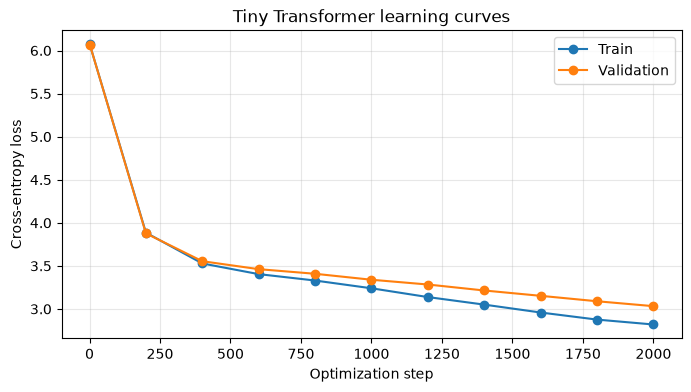

In [17]:
steps_seen = [row["step"] for row in history]
plt.figure(figsize=(8, 4))
plt.plot(steps_seen, [row["train_loss"] for row in history], marker="o", label="Train")
plt.plot(
    steps_seen,
    [row["validation_loss"] for row in history],
    marker="o",
    label="Validation",
)
plt.xlabel("Optimization step")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer learning curves")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 12. Reload the Best Checkpoint

Reconstruct both the tokenizer and model from saved configuration rather than relying on live notebook variables. The restored logits should exactly match the saved model in evaluation mode.

In [18]:
try:
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
except TypeError:  # Compatibility with older PyTorch releases.
    checkpoint = torch.load(checkpoint_path, map_location=device)
restored_tokenizer = BytePairTokenizer.from_state_dict(checkpoint["tokenizer_state"])
restored_model = TinyTransformerLM(**checkpoint["model_config"]).to(device)
restored_model.load_state_dict(checkpoint["model_state_dict"])
restored_model.eval()

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
with torch.no_grad():
    live_logits = model(example_inputs)
    restored_logits = restored_model(example_inputs)

print(
    f"Restored step {checkpoint['step']} with validation loss "
    f"{checkpoint['validation_loss']:.3f}"
)
assert restored_tokenizer.decode(restored_tokenizer.encode("Checkpoint ✓")) == "Checkpoint ✓"
assert torch.equal(live_logits, restored_logits)

Restored step 2000 with validation loss 3.033


## 13. Generate Trained Samples

In [19]:
sample_length = 80 if fast_dev_run else 400
prompt = "ROMEO:\n"

print("GREEDY\n------")
print(generate(restored_model, restored_tokenizer, prompt, sample_length, temperature=0))
print("\nTOP-K, TEMPERATURE 0.8\n----------------------")
print(generate(restored_model, restored_tokenizer, prompt, sample_length, temperature=0.8, top_k=40))

GREEDY
------
ROMEO:
The say say say my lord,
Thou criends that shall be speak of this say,
And that well so say says that sure that that shall be say,
And shall be a from heavends that shall be sure to my say,
And that shall be say say say say say say.

LUCESTER:
The say my lord, and say say.

LUCESTER:
The say my lord, and that my lord,
And that shall be say say say say say say their supon to my lord,
That shall be so my lord, and say say say.

LUCESTER:
The say my lord, and say say.

LUCESTER:
The say say say say say say say say.

LUCESTER:
The sir, my lord, and say say.

LUCESTER:
The say my lord, and say say.

LUCESTER:
The we sa

TOP-K, TEMPERATURE 0.8
----------------------
ROMEO:
Shall we will puch shall. To many hear a crame?
O LAUCESTER:
In clany lifewar, and ad, pleak,
Hare noth to saintlege with at more that callent my lord,
Butly my know was to dand, and offer words my lord;
Siction! what now go, thus lord.

Pranst:
Ay, my graved the cien, let that for goted, by this first

## 14. Interpreting the Result

Look for progressive levels of learning rather than perfect prose:

- valid bytes and punctuation;
- line breaks and speaker-name formatting;
- common word fragments and short phrases;
- eventually, longer locally plausible patterns.

Training loss measures next-token prediction, not factuality, reasoning, or literary quality. Increasing model size and training time improves capacity, but this small corpus also makes memorization more likely.

## 15. Things to Try

- Compare character/byte tokenization with 128, 256, and 512 BPE merges.
- Change `context_length` and observe both sample quality and GPU memory use.
- Replace learned positional embeddings with the sinusoidal encoding from the fundamentals notebook.
- Increase the number of blocks or embedding width while tracking parameter count and runtime.
- Compare greedy, unrestricted sampling, and several top-k/temperature combinations using the same prompt.
- Inspect attention weights by replacing one library block with a custom diagnostic block.

## Troubleshooting

- If training is slow, confirm Colab is using a GPU; use `FAST_DEV_RUN=1` only to test the pipeline.
- If memory is exhausted, lower `batch_size` first, then `context_length`.
- If loss becomes non-finite, reduce the learning rate and keep gradient clipping enabled.
- If downloaded data fails checksum verification, remove the fallback file and retry; never train silently on unexpected content.
- If generated text is repetitive, raise temperature slightly or increase `top_k`. If it is chaotic, lower them.
- An untrained byte-level model may emit invalid UTF-8 byte combinations. The tokenizer displays those as `�`; they should become less common as training improves.

**References:** [Tiny Shakespeare](https://github.com/karpathy/char-rnn/tree/master/data/tinyshakespeare) and [Attention Is All You Need](https://arxiv.org/html/1706.03762v7).